# Demand Forecasting — Generic Modeling Notebook

**Role in the pipeline**

```
Raw Company Data → Feature Engineering → **Modeling (this notebook)** → Price Optimization
```

This notebook turns a *clean engineered dataset* into a **validated, saved demand-forecasting model**:

`Feature selection → Preprocessing → Time-based split → Training → Evaluation → Model selection → Saving`

**Out of scope (by design):** price optimization, recommended prices, price elasticity and profit optimization. Those belong to downstream notebooks that consume the artifacts saved here.

**Generic by construction:** no feature list, Product ID or Store ID is hard-coded. Features are discovered from the data, so a different company's engineered file (with a different set of columns) trains with no code changes.

## 1. Imports

In [1]:
import json
import re
import subprocess
import sys
import tempfile
import time
import warnings
from datetime import datetime
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, OrdinalEncoder, StandardScaler

try:                                   # `display` is built into Jupyter; fall back to print elsewhere
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. Configuration

Everything that may differ between companies or projects lives in this one cell.
Column **names** are configured here — never column **values** (no Product IDs / Store IDs).

In [2]:
# ----------------------------------------------------------------------------
# Paths (folder names are matched case-insensitively, e.g. "Data" vs "data")
# ----------------------------------------------------------------------------
def find_dir(root: Path, name: str) -> Path:
    '''Existing sub-folder of `root` matching `name` case-insensitively, else `root/name`.'''
    if root.exists():
        for child in root.iterdir():
            if child.is_dir() and child.name.lower() == name.lower():
                return child
    return root / name

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
DATA_DIR     = find_dir(PROJECT_ROOT, "Data")
MODELS_DIR   = find_dir(PROJECT_ROOT, "Models")

DATA_PATH        = DATA_DIR / "demand_forecasting_engineered.csv"   # <- configurable input
PREDICTIONS_PATH = DATA_DIR / "demand_predictions.csv"
MODEL_PATH       = MODELS_DIR / "demand_forecasting_model.pkl"
METADATA_PATH    = MODELS_DIR / "model_metadata.json"

# ----------------------------------------------------------------------------
# Target, date and identifiers (names only)
# ----------------------------------------------------------------------------
TARGET_COLUMN = "Demand"
DATE_COLUMN   = "Date"

IDENTIFIER_COLUMNS          = ["Product_ID", "Store_ID"]   # treated as CATEGORICAL, never numeric
USE_IDENTIFIERS_AS_FEATURES = True

# ----------------------------------------------------------------------------
# Feature exclusion rules (matching ignores case, spaces and underscores)
# ----------------------------------------------------------------------------
EXCLUDED_FEATURES = [
    "Demand",      # the target
    "Date",        # used for the time split / ordering only
    "Unit_Cost",   # business input (cost side), not a demand driver
]
# Raw business OUTCOMES that are the target in disguise or a consequence of it:
LEAKAGE_RISK_COLUMNS = [
    "Units_Sold", "Units_Ordered", "Quantity_Sold", "Sales",
    "Revenue", "Profit", "Demand_Forecast", "Forecast",
]
EXTRA_EXCLUDED_FEATURES = []      # add company-specific columns to drop here

MAX_UNIQUE_RATIO = 0.5            # categorical column with >50% unique values (and >100 levels) = row key, dropped
LEAKAGE_CORR_WARN = 0.95          # |corr(feature, target)| on TRAIN only -> warning
LEAKAGE_CORR_DROP = 0.995         # |corr| on TRAIN only -> near-duplicate of target, dropped

# Legacy column names -> canonical names (no-op when the file already uses canonical names)
APPLY_LEGACY_COLUMN_ALIASES = True
LEGACY_COLUMN_ALIASES = {
    "Store ID": "Store_ID", "Product ID": "Product_ID", "Inventory Level": "Inventory",
    "Competitor Pricing": "Competitor_Price", "Weather Condition": "Weather",
    "Units Sold": "Units_Sold", "Units Ordered": "Units_Ordered", "Unit Cost": "Unit_Cost",
}

# ----------------------------------------------------------------------------
# Splitting & validation
# ----------------------------------------------------------------------------
TEST_SIZE       = 0.20     # newest 20% of the dates -> untouched test set
TEST_START_DATE = None     # optional override, e.g. "2023-08-01" (overrides TEST_SIZE)
VALIDATION_SIZE = 0.20     # newest 20% of the TRAIN dates -> validation hold-out (model comparison)
N_CV_SPLITS     = 4        # expanding-window folds for time-based validation
RANDOM_STATE    = 42

# ----------------------------------------------------------------------------
# Categorical encoding (keeps wide ID columns scalable)
# ----------------------------------------------------------------------------
MAX_ONEHOT_CATEGORIES  = 50    # one-hot width cap per column (rarer levels pooled into "infrequent")
MIN_CATEGORY_FREQUENCY = 10    # levels with fewer training rows are pooled as "infrequent"
NATIVE_MAX_CATEGORIES  = 250   # HistGradientBoosting native-categorical limit is 255

# ----------------------------------------------------------------------------
# Baselines, error analysis, importance
# ----------------------------------------------------------------------------
BASELINE_NAIVE_COLUMN   = "Previous_Demand"
BASELINE_ROLLING_COLUMN = "Previous_7Day_Avg_Demand"
PERMUTATION_MAX_ROWS    = 5000
PERMUTATION_REPEATS     = 3
TOP_N_FEATURES          = 15

# ----------------------------------------------------------------------------
# Historical reference (for the final comparison ONLY - never used for selection)
# ----------------------------------------------------------------------------
HISTORICAL_REFERENCE = {"MAE": 13.75, "RMSE": 17.94, "R2": 0.847}
LEGACY_FEATURES = [
    "Price", "Discount", "Promotion", "Competitor_Price", "Price_Difference", "Price_Ratio",
    "Effective_Price", "Promotion_Discount", "Price_Change", "Price_Change_Pct", "Previous_Demand",
    "Previous_7Day_Avg_Demand", "Demand_Trend", "Inventory", "Inventory_Coverage_Days", "Category",
    "Region", "Weather", "Seasonality", "Epidemic", "Year", "Month", "Day", "DayOfWeek", "IsWeekend",
    "Weekend_Promotion", "Low_Inventory", "Store_ID", "Product_ID",
]
RUN_LEGACY_SPLIT_DIAGNOSTIC = True      # diagnostic only; nothing from it is saved or used for selection
LEGACY_SPLIT_DATE           = "2023-08-01"

print("Project root :", PROJECT_ROOT)
print("Input data   :", DATA_PATH)

Project root : e:\Dynamic_Pricing_Optimizer
Input data   : e:\Dynamic_Pricing_Optimizer\Data\demand_forecasting_engineered.csv


## 3. Load Engineered Dataset

Loads the file produced by the Feature Engineering notebook, validates the two required columns
(target and date), sorts chronologically and drops rows that cannot be used for supervised training
(missing target or date).

In [3]:
def normalize_name(name) -> str:
    '''Case/space/underscore-insensitive key:  'Units Sold' == 'units_sold' == 'UnitsSold'.'''
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


def load_engineered_dataset(path, target_column, date_column, apply_aliases=True, aliases=None):
    '''Load + validate the engineered dataset. Returns (df, applied_renames, n_rows_dropped).'''
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(
            f"Engineered dataset not found: {path}\n"
            "Run Feature_Engineering.ipynb first, or update DATA_PATH in the configuration cell."
        )
    raw = pd.read_csv(path)

    renames = {}
    if apply_aliases:
        for old, new in (aliases or {}).items():
            if old in raw.columns and new not in raw.columns:
                renames[old] = new
        raw = raw.rename(columns=renames)

    for column, role in [(target_column, "target"), (date_column, "date")]:
        if column not in raw.columns:
            raise ValueError(
                f"Required {role} column '{column}' was not found in {path.name}.\n"
                f"Available columns: {list(raw.columns)}"
            )

    raw[date_column]   = pd.to_datetime(raw[date_column], errors="coerce")
    raw[target_column] = pd.to_numeric(raw[target_column], errors="coerce")
    usable = raw[date_column].notna() & raw[target_column].notna()
    n_dropped = int((~usable).sum())
    raw = raw.loc[usable]
    if raw.empty:
        raise ValueError("No usable rows remain after removing rows with a missing date or target.")

    id_cols = [c for c in raw.columns if normalize_name(c) in {normalize_name(i) for i in IDENTIFIER_COLUMNS}]
    raw = raw.sort_values([date_column] + id_cols, kind="mergesort").reset_index(drop=True)
    return raw, renames, n_dropped


df, applied_renames, n_dropped_rows = load_engineered_dataset(
    DATA_PATH, TARGET_COLUMN, DATE_COLUMN, APPLY_LEGACY_COLUMN_ALIASES, LEGACY_COLUMN_ALIASES
)
if applied_renames:
    print("Legacy column names mapped to canonical names:", applied_renames)
if n_dropped_rows:
    print(f"Dropped {n_dropped_rows:,} rows with a missing/invalid date or target.")
df.head()

Legacy column names mapped to canonical names: {'Store ID': 'Store_ID', 'Product ID': 'Product_ID', 'Inventory Level': 'Inventory', 'Competitor Pricing': 'Competitor_Price', 'Weather Condition': 'Weather', 'Units Sold': 'Units_Sold', 'Units Ordered': 'Units_Ordered'}


,Date,Store_ID,Product_ID,Category,Region,Inventory,Units_Sold,Units_Ordered,Price,Discount,Weather,Promotion,Competitor_Price,Seasonality,Epidemic,Demand,Year,Month,Day,DayOfWeek,WeekOfYear,Quarter,IsWeekend,Previous_Price,Price_Change,Price_Change_Pct,Effective_Price,Price_Difference,Price_Ratio,Previous_Demand,Previous_7Day_Avg_Demand,Demand_Trend,Inventory_Coverage_Days,Low_Inventory,Weekend_Promotion,Promotion_Discount
0,2022-01-08,S001,P0001,Electronics,North,308.0000,96,248,68.5600,10.0000,Snowy,1,80.9900,Winter,0,113.0000,2022,1,8,5,1,1,1,66.0700,2.4900,3.7687,61.7040,-12.4300,0.8465,87.0000,105.8571,-18.8571,2.9096,0,1,10.0000
1,2022-01-08,S001,P0002,Clothing,North,77.0000,77,208,76.3000,15.0000,Snowy,1,90.6600,Winter,0,208.0000,2022,1,8,5,1,1,1,58.5800,17.7200,30.2492,64.8550,-14.3600,0.8416,94.0000,136.4286,-42.4286,0.5644,1,1,15.0000
2,2022-01-08,S001,P0003,Clothing,North,308.0000,109,0,54.1500,15.0000,Snowy,1,58.1900,Winter,0,142.0000,2022,1,8,5,1,1,1,43.0400,11.1100,25.8132,46.0275,-4.0400,0.9306,71.0000,122.1429,-51.1429,2.5216,0,1,15.0000
3,2022-01-08,S001,P0004,Electronics,North,155.0000,32,0,69.3700,20.0000,Snowy,1,78.4200,Winter,0,36.0000,2022,1,8,5,1,1,1,99.2700,-29.9000,-30.1199,55.4960,-9.0500,0.8846,57.0000,61.2857,-4.2857,2.5291,0,1,20.0000
4,2022-01-08,S001,P0005,Groceries,North,"1,293.0000",95,0,53.5700,5.0000,Snowy,0,59.5300,Winter,0,83.0000,2022,1,8,5,1,1,1,56.0200,-2.4500,-4.3734,50.8915,-5.9600,0.8999,97.0000,110.5714,-13.5714,11.6938,0,0,0.0000


## 4. Dataset Overview

In [4]:
def print_dataset_overview(frame, target_column, date_column, identifier_columns):
    print(f"Dataset shape     : {frame.shape}")
    print(f"Number of rows    : {len(frame):,}")
    print(f"Number of columns : {frame.shape[1]}")
    print(f"Date range        : {frame[date_column].min():%Y-%m-%d} -> {frame[date_column].max():%Y-%m-%d}"
          f"  ({frame[date_column].nunique():,} distinct dates)")
    id_norm = {normalize_name(c): c for c in identifier_columns}
    for column in frame.columns:
        if normalize_name(column) in id_norm:
            kind = {"productid": "products", "storeid": "stores"}.get(normalize_name(column), "unique values")
            print(f"Number of {kind:<9}: {frame[column].nunique():,}   ({column})")
    print()
    print("Target distribution:")
    desc = frame[target_column].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
    display(desc.to_frame(target_column).T)
    print(f"Skewness: {frame[target_column].skew():.2f} | zero-demand rows: {(frame[target_column] == 0).mean():.2%}"
          f" | negative values: {(frame[target_column] < 0).sum():,}")

print_dataset_overview(df, TARGET_COLUMN, DATE_COLUMN, IDENTIFIER_COLUMNS)

column_profile = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_%": (df.isna().mean() * 100).round(2),
    "unique": df.nunique(),
})
display(column_profile)

Dataset shape     : (75300, 36)
Number of rows    : 75,300
Number of columns : 36
Date range        : 2022-01-08 -> 2024-01-30  (753 distinct dates)
Number of stores   : 5   (Store_ID)
Number of products : 20   (Product_ID)

Target distribution:


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Demand,"75,300.0000",104.2523,46.9991,4.0000,17.0000,34.0000,71.0000,100.0000,132.0000,188.0000,234.0000,430.0000


Skewness: 0.61 | zero-demand rows: 0.00% | negative values: 0


,dtype,missing_%,unique
Date,datetime64[ns],0.0000,753
Store_ID,object,0.0000,5
Product_ID,object,0.0000,20
Category,object,0.0000,5
Region,object,0.0000,4
Inventory,float64,0.0000,1424
Units_Sold,int64,0.0000,330
Units_Ordered,int64,0.0000,996
Price,float64,0.0000,15368
Discount,float64,0.0000,6


## 5. Target Definition

The target is `Demand`. It is never an input feature. If the column is missing, loading already stops with a clear error;
the assertion below makes the contract explicit.

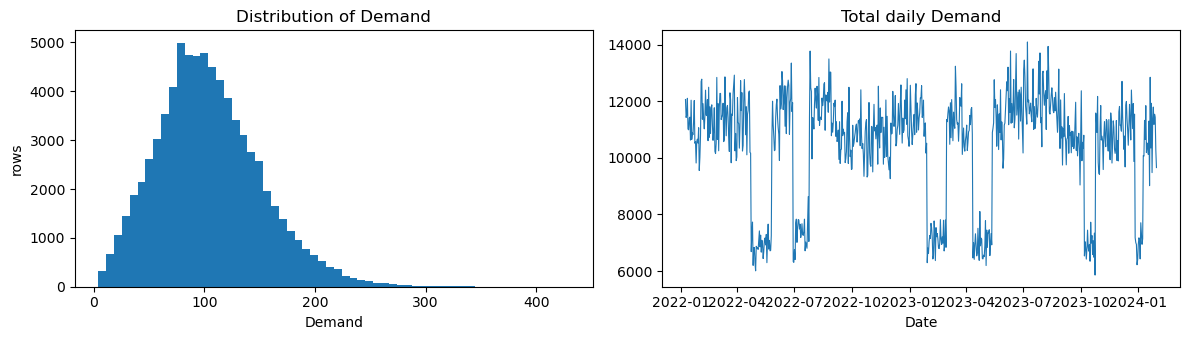

TARGET_COLUMN = 'Demand'


In [5]:
if TARGET_COLUMN not in df.columns:
    raise ValueError(f"Target column '{TARGET_COLUMN}' is required but missing. Columns: {list(df.columns)}")
assert pd.api.types.is_numeric_dtype(df[TARGET_COLUMN]), "Target must be numeric."

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(df[TARGET_COLUMN], bins=60)
axes[0].set(title=f"Distribution of {TARGET_COLUMN}", xlabel=TARGET_COLUMN, ylabel="rows")
daily = df.groupby(DATE_COLUMN)[TARGET_COLUMN].sum()
axes[1].plot(daily.index, daily.values, linewidth=0.8)
axes[1].set(title=f"Total daily {TARGET_COLUMN}", xlabel=DATE_COLUMN)
plt.tight_layout(); plt.show()
print(f"TARGET_COLUMN = '{TARGET_COLUMN}'")

## 6. Feature Selection

`select_features()` decides — from column names and dtypes only — which columns may be used as model inputs:

* **Always excluded:** the target, the date, configured exclusions (e.g. `Unit_Cost`) and *raw business outcomes* that would leak the answer (e.g. `Units_Sold`, `Revenue`).
* **Identifiers** (`Product_ID`, `Store_ID`, any `*_ID` column) are forced to **categorical**, even when stored as integers, so they are never treated as a magnitude.
* Other numeric columns → numeric features; text/categorical columns → categorical features.
* Near-unique text columns (row keys), datetime columns and date-like text columns are dropped.

Statistics-based checks (constant columns, correlation audit for leakage) run **after the split, on the training period only**.

In [6]:
ID_NAME_PATTERN = re.compile(r"(^|[\s_\-])id$", flags=re.IGNORECASE)
DATE_TEXT_PATTERN = re.compile(r"^\s*(\d{4}[-/.]\d{1,2}[-/.]\d{1,2}|\d{1,2}[-/.]\d{1,2}[-/.]\d{2,4})")


def looks_like_datetime_text(series, sample_size=200):
    '''True for text columns holding dates/timestamps (CSV files do not store dtypes).'''
    values = series.dropna()
    if values.empty:
        return False
    sample = values.astype(str).sample(n=min(sample_size, len(values)), random_state=0)
    return bool(sample.str.match(DATE_TEXT_PATTERN).mean() >= 0.9)


def select_features(df, target_column="Demand", date_column=DATE_COLUMN, excluded_features=None,
                    leakage_risk_columns=None, identifier_columns=None, use_identifiers=True,
                    max_unique_ratio=0.5):
    '''Discover usable model inputs. Uses column names and dtypes only (no target statistics).

    Returns a dict with: feature_columns, numeric_features, categorical_features,
    identifier_features and excluded ({column: reason}).
    '''
    configured = {normalize_name(c) for c in (excluded_features or [])}
    leakage    = {normalize_name(c) for c in (leakage_risk_columns or [])}
    id_names   = {normalize_name(c) for c in (identifier_columns or [])}

    numeric, categorical, identifiers, excluded = [], [], [], {}
    for column in df.columns:
        key, series = normalize_name(column), df[column]
        if key == normalize_name(target_column):
            excluded[column] = "target column"
        elif key == normalize_name(date_column):
            excluded[column] = "date column (time split only)"
        elif key in configured:
            excluded[column] = "configured exclusion"
        elif key in leakage:
            excluded[column] = "leakage risk (raw business outcome)"
        elif pd.api.types.is_datetime64_any_dtype(series):
            excluded[column] = "datetime column"
        else:
            is_id = key in id_names or bool(ID_NAME_PATTERN.search(str(column)))
            is_text = not pd.api.types.is_numeric_dtype(series)
            if is_id and not use_identifiers:
                excluded[column] = "identifier (USE_IDENTIFIERS_AS_FEATURES=False)"
            elif is_text and not is_id and looks_like_datetime_text(series):
                excluded[column] = "date-like text column (use the engineered date parts instead)"
            elif is_id or is_text:
                n_unique = series.nunique(dropna=True)
                if n_unique > 100 and n_unique / max(len(series), 1) > max_unique_ratio:
                    excluded[column] = "near-unique key (not generalisable)"
                else:
                    categorical.append(column)
                    if is_id:
                        identifiers.append(column)
            else:
                numeric.append(column)

    return {
        "feature_columns": [c for c in df.columns if c in numeric or c in categorical],
        "numeric_features": numeric,
        "categorical_features": categorical,
        "identifier_features": identifiers,
        "excluded": excluded,
    }


def print_feature_selection(selection, frame):
    print(f"Selected {len(selection['feature_columns'])} features "
          f"({len(selection['numeric_features'])} numeric, {len(selection['categorical_features'])} categorical)\n")
    rows = []
    for column in selection["feature_columns"]:
        kind = "categorical (identifier)" if column in selection["identifier_features"] else (
               "categorical" if column in selection["categorical_features"] else "numeric")
        rows.append({"Feature": column, "Type": kind, "Missing %": frame[column].isna().mean() * 100,
                     "Unique": frame[column].nunique()})
    display(pd.DataFrame(rows))
    print("\nExcluded columns:")
    display(pd.DataFrame({"Reason": selection["excluded"]}))


feature_selection = select_features(
    df, target_column=TARGET_COLUMN, date_column=DATE_COLUMN,
    excluded_features=EXCLUDED_FEATURES + EXTRA_EXCLUDED_FEATURES,
    leakage_risk_columns=LEAKAGE_RISK_COLUMNS,
    identifier_columns=IDENTIFIER_COLUMNS, use_identifiers=USE_IDENTIFIERS_AS_FEATURES,
    max_unique_ratio=MAX_UNIQUE_RATIO,
)
print_feature_selection(feature_selection, df)

Selected 32 features (26 numeric, 6 categorical)



,Feature,Type,Missing %,Unique
0,Store_ID,categorical (identifier),0.0000,5
1,Product_ID,categorical (identifier),0.0000,20
2,Category,categorical,0.0000,5
3,Region,categorical,0.0000,4
4,Inventory,numeric,0.0000,1424
5,Price,numeric,0.0000,15368
6,Discount,numeric,0.0000,6
7,Weather,categorical,0.0000,4
8,Promotion,numeric,0.0000,2
9,Competitor_Price,numeric,0.0000,15935



Excluded columns:


,Reason
Date,date column (time split only)
Units_Sold,leakage risk (raw business outcome)
Units_Ordered,leakage risk (raw business outcome)
Demand,target column


## 7. Train/Test Time Split

Demand forecasting must respect time, so there is **no random split**. Rows are ordered by date, the *oldest* part is the
training set and the *newest* part is the test set. The cut is made on distinct **dates** (not rows), so no calendar day is
ever shared between train and test — important for panel data with many products/stores per day.

The same function is reused later to carve a validation hold-out out of the training period.

In [7]:
def time_based_split(frame, date_column, test_size=0.2, test_start_date=None):
    '''Chronological split on distinct dates. Returns (older_df, newer_df, cutoff_timestamp).'''
    dates = np.sort(frame[date_column].drop_duplicates().to_numpy())
    if len(dates) < 5:
        raise ValueError("Need at least 5 distinct dates for a time-based split.")
    if test_start_date is not None:
        cutoff = pd.Timestamp(test_start_date)
    else:
        cutoff = pd.Timestamp(dates[int(np.floor(len(dates) * (1 - test_size)))])
    older = frame[frame[date_column] < cutoff]
    newer = frame[frame[date_column] >= cutoff]
    if older.empty or newer.empty:
        raise ValueError(f"Split at {cutoff:%Y-%m-%d} leaves an empty train or test set.")
    assert older[date_column].max() < newer[date_column].min(), "Time leakage: periods overlap."
    return older, newer, cutoff


train_df, test_df, TEST_START = time_based_split(df, DATE_COLUMN, TEST_SIZE, TEST_START_DATE)

print("Training period:")
print(f"{train_df[DATE_COLUMN].min():%Y-%m-%d} -> {train_df[DATE_COLUMN].max():%Y-%m-%d}\n")
print("Testing period:")
print(f"{test_df[DATE_COLUMN].min():%Y-%m-%d} -> {test_df[DATE_COLUMN].max():%Y-%m-%d}\n")
print("Training rows:", f"{len(train_df):,}  ({len(train_df) / len(df):.1%})")
print("Testing rows :", f"{len(test_df):,}  ({len(test_df) / len(df):.1%})")

assert train_df[DATE_COLUMN].max() < test_df[DATE_COLUMN].min()
print(f"\nVerified: max(train_date) {train_df[DATE_COLUMN].max():%Y-%m-%d} < min(test_date) {test_df[DATE_COLUMN].min():%Y-%m-%d}")

# --- Training-period-only checks on the selected features (no test information is used) ---
def prune_unusable_features(train_frame, selection, target_column, corr_warn=0.95, corr_drop=0.995):
    '''Drop features that are all-missing/constant in TRAIN or are a near-duplicate of the target (leakage).'''
    sel = {k: (list(v) if isinstance(v, list) else dict(v)) for k, v in selection.items()}
    removed = {}
    for column in sel["feature_columns"]:
        series = train_frame[column]
        if series.notna().sum() == 0:
            removed[column] = "all values missing in the training period"
        elif series.nunique(dropna=True) <= 1:
            removed[column] = "constant in the training period"

    numeric_left = [c for c in sel["numeric_features"] if c not in removed]
    audit = pd.DataFrame(columns=["Feature", "AbsCorrWithTarget"])
    if numeric_left:
        corr = train_frame[numeric_left].astype(float).corrwith(train_frame[target_column].astype(float)).abs()
        audit = corr.sort_values(ascending=False).rename("AbsCorrWithTarget").rename_axis("Feature").reset_index()
        for column, value in corr.items():
            if value >= corr_drop:
                removed[column] = f"near-duplicate of target (|corr|={value:.4f}) - leakage"
            elif value >= corr_warn:
                print(f"WARNING: '{column}' has |corr|={value:.3f} with the target in training data - verify it is not leakage.")

    for column, reason in removed.items():
        for key in ("feature_columns", "numeric_features", "categorical_features", "identifier_features"):
            if column in sel[key]:
                sel[key].remove(column)
        sel["excluded"][column] = reason
    return sel, audit, removed


feature_selection, leakage_audit, pruned = prune_unusable_features(
    train_df, feature_selection, TARGET_COLUMN, LEAKAGE_CORR_WARN, LEAKAGE_CORR_DROP)

FEATURE_COLUMNS     = feature_selection["feature_columns"]
NUMERIC_FEATURES    = feature_selection["numeric_features"]
CATEGORICAL_FEATURES = feature_selection["categorical_features"]
EXCLUDED_REPORT     = feature_selection["excluded"]

print("\nFeatures removed after training-period checks:", pruned if pruned else "none")
print("Strongest feature/target correlations (train only, numeric features):")
display(leakage_audit.head(5))
print(f"Final feature count: {len(FEATURE_COLUMNS)}  ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)")
assert TARGET_COLUMN not in FEATURE_COLUMNS and DATE_COLUMN not in FEATURE_COLUMNS

Training period:
2022-01-08 -> 2023-09-01

Testing period:
2023-09-02 -> 2024-01-30

Training rows: 60,200  (79.9%)
Testing rows : 15,100  (20.1%)

Verified: max(train_date) 2023-09-01 < min(test_date) 2023-09-02

Features removed after training-period checks: none
Strongest feature/target correlations (train only, numeric features):


,Feature,AbsCorrWithTarget
0,Previous_7Day_Avg_Demand,0.4999
1,Price_Change_Pct,0.4244
2,Epidemic,0.3663
3,Previous_Demand,0.3583
4,Price_Change,0.3547


Final feature count: 32  (26 numeric, 6 categorical)


## 8. Preprocessing

One reusable `ColumnTransformer` factory, fitted **only inside each training fold** because it lives inside the sklearn `Pipeline`.

| Feature kind | Linear / Random Forest | HistGradientBoosting |
|---|---|---|
| **Numeric** | median imputation (+ missing-indicator columns so "was missing" is preserved); scaling for Ridge only | passed through with `NaN` kept — the model learns its own handling of missing values, so distributions are not distorted |
| **Categorical** (incl. IDs) | missing → `"Missing"`, then one-hot **capped at `MAX_ONEHOT_CATEGORIES`** levels (rare levels pooled; unseen levels safe) | missing → `"Missing"`, ordinal codes consumed as **native categorical** features (no false ordering), rare levels pooled, unseen → treated as missing |

The width cap is what keeps thousands of Product/Store IDs tractable: nothing is blindly one-hot encoded.

Only built-in numpy/sklearn callables are used, so the saved pipeline can be loaded in any other process (e.g. Streamlit) without this notebook's code.

In [8]:
# Module-level, built-in callables only -> the fitted pipeline stays picklable/loadable anywhere.
_as_object = partial(np.asarray, dtype=object)
_as_str    = partial(np.asarray, dtype=str)
_as_float  = partial(np.asarray, dtype=float)


def build_preprocessor(numeric_features, categorical_features, encoding="onehot", scale_numeric=False):
    '''ColumnTransformer with separate numeric / categorical pipelines.
    encoding='onehot' (linear, random forest) or 'native' (HistGradientBoosting).'''
    transformers = []
    if numeric_features:
        if encoding == "native":
            numeric_pipe = FunctionTransformer(_as_float, feature_names_out="one-to-one")   # NaN kept for HGB
        else:
            steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]
            if scale_numeric:
                steps.append(("scale", StandardScaler()))
            numeric_pipe = Pipeline(steps)
        transformers.append(("num", numeric_pipe, list(numeric_features)))

    if categorical_features:
        if encoding == "native":
            encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=np.nan,
                                     min_frequency=MIN_CATEGORY_FREQUENCY, max_categories=NATIVE_MAX_CATEGORIES)
        else:
            encoder = OneHotEncoder(handle_unknown="infrequent_if_exist", sparse_output=False,
                                    min_frequency=MIN_CATEGORY_FREQUENCY, max_categories=MAX_ONEHOT_CATEGORIES)
        categorical_pipe = Pipeline([
            ("to_object", FunctionTransformer(_as_object, feature_names_out="one-to-one")),
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("to_str", FunctionTransformer(_as_str, feature_names_out="one-to-one")),   # IDs 1 / "1" -> same level
            ("encode", encoder),
        ])
        transformers.append(("cat", categorical_pipe, list(categorical_features)))

    return ColumnTransformer(transformers, remainder="drop", sparse_threshold=0.0)


# Model registry: adding a model = adding one entry (no other code changes)
MODEL_SPECS = {
    "ridge": {
        "label": "Ridge Regression", "estimator": Ridge, "encoding": "onehot", "scale": True, "is_tree": False,
        "defaults": {"alpha": 1.0},
        "grid": [],
    },
    "random_forest": {
        "label": "Random Forest", "estimator": RandomForestRegressor, "encoding": "onehot", "scale": False, "is_tree": True,
        "defaults": {"n_estimators": 100, "min_samples_leaf": 5, "max_features": 0.5, "n_jobs": -1, "random_state": RANDOM_STATE},
        "grid": [{"min_samples_leaf": 10}, {"max_features": 0.33}, {"min_samples_leaf": 2, "max_depth": 20}],
    },
    "hist_gradient_boosting": {
        "label": "HistGradientBoosting", "estimator": HistGradientBoostingRegressor, "encoding": "native", "scale": False, "is_tree": True,
        "defaults": {"max_iter": 300, "learning_rate": 0.05, "max_leaf_nodes": 31, "min_samples_leaf": 20,
                     "early_stopping": False, "random_state": RANDOM_STATE},
        "grid": [{"max_iter": 500, "learning_rate": 0.03}, {"max_leaf_nodes": 15},
                 {"max_leaf_nodes": 63}, {"min_samples_leaf": 50}],
    },
}


def make_pipeline(model_key, numeric_features, categorical_features, **overrides):
    '''preprocessor -> model, as ONE sklearn Pipeline.'''
    spec = MODEL_SPECS[model_key]
    params = {**spec["defaults"], **overrides}
    if spec["encoding"] == "native" and categorical_features:
        # numeric columns come first in the transformed matrix, categorical codes last
        params["categorical_features"] = np.array([False] * len(numeric_features) + [True] * len(categorical_features))
    return Pipeline([
        ("preprocessor", build_preprocessor(numeric_features, categorical_features, spec["encoding"], spec["scale"])),
        ("model", spec["estimator"](**params)),
    ])


preview = make_pipeline("hist_gradient_boosting", NUMERIC_FEATURES, CATEGORICAL_FEATURES)
print(preview)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(sparse_threshold=0.0,
                                   transformers=[('num',
                                                  FunctionTransformer(feature_names_out='one-to-one',
                                                                      func=functools.partial(<built-in function asarray>, dtype=<class 'float'>)),
                                                  ['Inventory', 'Price',
                                                   'Discount', 'Promotion',
                                                   'Competitor_Price',
                                                   'Epidemic', 'Year', 'Month',
                                                   'Day', 'DayOfWeek',
                                                   'WeekOfYear', 'Quarter',
                                                   'IsWe...
                                                   'Weather',
                                   

## 9. Baseline

A model is only useful if it beats something trivial. The primary baseline is the **naive forecast**
`Previous_Demand` ("tomorrow = yesterday"); if that column does not exist, a **training-mean** baseline is used.
Missing naive values are filled with the *training* mean only. Two extra reference baselines are shown for context.

Shared helpers used throughout the notebook are defined here too.

In [9]:
def regression_metrics(y_true, y_pred):
    return {"MAE": float(mean_absolute_error(y_true, y_pred)),
            "RMSE": float(np.sqrt(mean_squared_error(y_true, y_pred))),
            "R2": float(r2_score(y_true, y_pred))}


def baseline_predictions(fit_frame, eval_frame):
    '''Naive baselines. Only `fit_frame` (older data) is used for any statistic.'''
    mean_value = float(fit_frame[TARGET_COLUMN].mean())
    preds = {"Baseline: training mean": np.full(len(eval_frame), mean_value)}
    for column, label in [(BASELINE_ROLLING_COLUMN, f"Baseline: {BASELINE_ROLLING_COLUMN}"),
                          (BASELINE_NAIVE_COLUMN, f"Baseline: {BASELINE_NAIVE_COLUMN} (naive)")]:
        if column in eval_frame.columns:
            preds[label] = eval_frame[column].astype(float).fillna(mean_value).to_numpy()
    return preds


FIT_LOG = []      # latest training date of every fit -> proof the test period was never trained on


def fit_pipeline(pipeline, fit_frame):
    '''Fit a CLONE on `fit_frame`. Refuses to train on anything at/after the test period.'''
    assert fit_frame[DATE_COLUMN].max() < TEST_START, "Leakage guard: training data reaches the test period!"
    FIT_LOG.append(fit_frame[DATE_COLUMN].max())
    fitted = clone(pipeline)
    start = time.perf_counter()
    fitted.fit(fit_frame[FEATURE_COLUMNS], fit_frame[TARGET_COLUMN])
    return fitted, time.perf_counter() - start


baseline_test_preds = baseline_predictions(train_df, test_df)
PRIMARY_BASELINE = (f"Baseline: {BASELINE_NAIVE_COLUMN} (naive)" if BASELINE_NAIVE_COLUMN in test_df.columns
                    else "Baseline: training mean")
baseline_table = pd.DataFrame(
    [{"Baseline": name, **regression_metrics(test_df[TARGET_COLUMN], pred)} for name, pred in baseline_test_preds.items()]
).sort_values("MAE").reset_index(drop=True)

if BASELINE_NAIVE_COLUMN in train_df.columns:
    n_missing = int(test_df[BASELINE_NAIVE_COLUMN].isna().sum())
    print(f"Primary baseline: '{BASELINE_NAIVE_COLUMN}' (naive); {n_missing:,} missing test values filled with the training mean.")
else:
    print(f"'{BASELINE_NAIVE_COLUMN}' not available -> primary baseline is the training-mean forecast.")
display(baseline_table)

baseline_metrics = regression_metrics(test_df[TARGET_COLUMN], baseline_test_preds[PRIMARY_BASELINE])
print(f"\nPrimary baseline ({PRIMARY_BASELINE}) on the test period -> "
      f"MAE {baseline_metrics['MAE']:.2f} | RMSE {baseline_metrics['RMSE']:.2f} | R2 {baseline_metrics['R2']:.3f}")

Primary baseline: 'Previous_Demand' (naive); 0 missing test values filled with the training mean.


,Baseline,MAE,RMSE,R2
0,Baseline: Previous_7Day_Avg_Demand,31.5963,40.6094,0.1527
1,Baseline: training mean,35.4505,44.4045,-0.0131
2,Baseline: Previous_Demand (naive),40.1385,51.8937,-0.3837



Primary baseline (Baseline: Previous_Demand (naive)) on the test period -> MAE 40.14 | RMSE 51.89 | R2 -0.384


## 10. Candidate Models

Three families, each wrapped in `preprocessor → model` pipelines:

1. **Ridge** — regularised linear model (interpretable reference).
2. **Random Forest** — bagged trees, robust with little tuning.
3. **HistGradientBoosting** — fast gradient boosting with native categorical + missing-value support.

To keep the **test set untouched**, candidates are compared on a *validation hold-out carved from the training period*
(older ~80% of the training dates → fit, newest ~20% of the training dates → validate).

In [10]:
inner_train_df, holdout_df, HOLDOUT_START = time_based_split(train_df, DATE_COLUMN, VALIDATION_SIZE)
print(f"Inner-train : {inner_train_df[DATE_COLUMN].min():%Y-%m-%d} -> {inner_train_df[DATE_COLUMN].max():%Y-%m-%d}  ({len(inner_train_df):,} rows)")
print(f"Validation  : {holdout_df[DATE_COLUMN].min():%Y-%m-%d} -> {holdout_df[DATE_COLUMN].max():%Y-%m-%d}  ({len(holdout_df):,} rows)\n")

candidate_results = []
for model_key, spec in MODEL_SPECS.items():
    pipeline = make_pipeline(model_key, NUMERIC_FEATURES, CATEGORICAL_FEATURES)
    fitted, seconds = fit_pipeline(pipeline, inner_train_df)
    pred = fitted.predict(holdout_df[FEATURE_COLUMNS])
    candidate_results.append({"Model": spec["label"], "Key": model_key,
                              **regression_metrics(holdout_df[TARGET_COLUMN], pred), "Fit seconds": seconds})
    print(f"trained {spec['label']:<24} in {seconds:6.1f}s")

Inner-train : 2022-01-08 -> 2023-05-03  (48,100 rows)
Validation  : 2023-05-04 -> 2023-09-01  (12,100 rows)

trained Ridge Regression         in    0.8s
trained Random Forest            in   13.8s
trained HistGradientBoosting     in    4.4s


## 11. Model Comparison

Sorted by **MAE ascending**. Why not rank by R²?

1. **MAE** is in demand units and maps directly to over/under-stocking cost; it is robust to a few extreme days.
2. **RMSE** is second: it penalises large misses, which matter for stock-outs.
3. **R²** is last: it is relative to variance, so it can look excellent while the average miss is still operationally large, and it is not comparable across datasets with different demand scales.

Validation hold-out comparison (older data fit -> newest training dates scored):


,Model,MAE,RMSE,R2
0,HistGradientBoosting,13.6054,18.0236,0.8714
1,Random Forest,17.9642,23.3617,0.7839
2,Ridge Regression,19.0176,24.6376,0.7597
3,Baseline: Previous_7Day_Avg_Demand,34.5051,45.0033,0.1982
4,Baseline: training mean,39.3455,51.6331,-0.0555
5,Baseline: Previous_Demand (naive),44.9765,58.7307,-0.3656


Best candidate on the hold-out: HistGradientBoosting  (MAE 13.605, RMSE 18.024, R2 0.871)


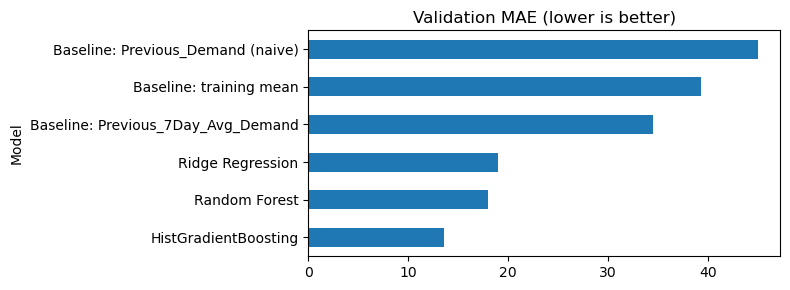

In [11]:
holdout_baselines = baseline_predictions(inner_train_df, holdout_df)
comparison_rows = [{"Model": name, "MAE": m["MAE"], "RMSE": m["RMSE"], "R2": m["R2"]}
                   for name, pred in holdout_baselines.items()
                   for m in [regression_metrics(holdout_df[TARGET_COLUMN], pred)]]
comparison_rows += [{k: r[k] for k in ("Model", "MAE", "RMSE", "R2")} for r in candidate_results]

holdout_comparison = pd.DataFrame(comparison_rows).sort_values("MAE").reset_index(drop=True)
print("Validation hold-out comparison (older data fit -> newest training dates scored):")
display(holdout_comparison)

best_holdout = holdout_comparison[~holdout_comparison["Model"].str.startswith("Baseline")].iloc[0]
print(f"Best candidate on the hold-out: {best_holdout['Model']}  (MAE {best_holdout['MAE']:.3f}, RMSE {best_holdout['RMSE']:.3f}, R2 {best_holdout['R2']:.3f})")

holdout_comparison.set_index("Model")["MAE"].sort_values().plot.barh(figsize=(8, 3), title="Validation MAE (lower is better)")
plt.tight_layout(); plt.show()

## 12. Time-Based Validation

A single hold-out can be lucky, so every candidate is also scored with an **expanding-window** validation
(`TimeSeriesSplit` over the distinct *dates* of the training period — never random K-Fold):
each fold trains on all older dates and validates on the next block of dates.

The strongest **tree-based** model (by default-settings CV MAE) then gets a small, deliberately lightweight
hyper-parameter comparison (a handful of variants, not a large search).

In [12]:
def expanding_window_splits(frame, date_column, n_splits):
    '''Yield (train_idx, validation_idx) positional indices; folds are cut on whole dates.'''
    codes, uniques = pd.factorize(frame[date_column], sort=True)
    for train_dates, val_dates in TimeSeriesSplit(n_splits=n_splits).split(np.arange(len(uniques))):
        yield (np.flatnonzero(codes <= train_dates[-1]),
               np.flatnonzero((codes >= val_dates[0]) & (codes <= val_dates[-1])))


def cv_evaluate(model_key, overrides, frame):
    pipeline = make_pipeline(model_key, NUMERIC_FEATURES, CATEGORICAL_FEATURES, **overrides)
    maes, rmses, r2s, start = [], [], [], time.perf_counter()
    for train_idx, val_idx in expanding_window_splits(frame, DATE_COLUMN, N_CV_SPLITS):
        fitted, _ = fit_pipeline(pipeline, frame.iloc[train_idx])
        val = frame.iloc[val_idx]
        m = regression_metrics(val[TARGET_COLUMN], fitted.predict(val[FEATURE_COLUMNS]))
        maes.append(m["MAE"]); rmses.append(m["RMSE"]); r2s.append(m["R2"])
    return {"CV MAE": float(np.mean(maes)), "CV MAE std": float(np.std(maes)), "CV RMSE": float(np.mean(rmses)),
            "CV R2": float(np.mean(r2s)), "Seconds": time.perf_counter() - start}


fold_info = []
for i, (tr, va) in enumerate(expanding_window_splits(train_df, DATE_COLUMN, N_CV_SPLITS), 1):
    fold_info.append({"Fold": i,
                      "Train": f"{train_df.iloc[tr][DATE_COLUMN].min():%Y-%m-%d} -> {train_df.iloc[tr][DATE_COLUMN].max():%Y-%m-%d}",
                      "Validate": f"{train_df.iloc[va][DATE_COLUMN].min():%Y-%m-%d} -> {train_df.iloc[va][DATE_COLUMN].max():%Y-%m-%d}",
                      "Train rows": len(tr), "Validation rows": len(va)})
display(pd.DataFrame(fold_info))

cv_rows = []
def record_cv(model_key, overrides, config_name):
    result = cv_evaluate(model_key, overrides, train_df)
    cv_rows.append({"Model": MODEL_SPECS[model_key]["label"], "Key": model_key, "Config": config_name,
                    "Overrides": dict(overrides), **result})
    print(f"CV  {MODEL_SPECS[model_key]['label']:<22} {config_name:<10} MAE {result['CV MAE']:.3f} (+/- {result['CV MAE std']:.3f})  [{result['Seconds']:.0f}s]")

# 1) default settings of every candidate
for model_key in MODEL_SPECS:
    record_cv(model_key, {}, "default")

# 2) lightweight hyper-parameter comparison for the strongest tree-based model
tree_defaults = [r for r in cv_rows if MODEL_SPECS[r["Key"]]["is_tree"]]
STRONGEST_TREE_KEY = min(tree_defaults, key=lambda r: r["CV MAE"])["Key"]
print(f"\nStrongest tree-based model: {MODEL_SPECS[STRONGEST_TREE_KEY]['label']} -> comparing {len(MODEL_SPECS[STRONGEST_TREE_KEY]['grid'])} hyper-parameter variants")
for i, overrides in enumerate(MODEL_SPECS[STRONGEST_TREE_KEY]["grid"], 1):
    record_cv(STRONGEST_TREE_KEY, overrides, f"variant {i}")

cv_results = (pd.DataFrame(cv_rows).sort_values(["CV MAE", "CV RMSE"]).reset_index(drop=True))
display(cv_results[["Model", "Config", "Overrides", "CV MAE", "CV MAE std", "CV RMSE", "CV R2", "Seconds"]])

,Fold,Train,Validate,Train rows,Validation rows
0,1,2022-01-08 -> 2022-05-09,2022-05-10 -> 2022-09-06,12200,12000
1,2,2022-01-08 -> 2022-09-06,2022-09-07 -> 2023-01-04,24200,12000
2,3,2022-01-08 -> 2023-01-04,2023-01-05 -> 2023-05-04,36200,12000
3,4,2022-01-08 -> 2023-05-04,2023-05-05 -> 2023-09-01,48200,12000


CV  Ridge Regression       default    MAE 18.388 (+/- 0.525)  [3s]
CV  Random Forest          default    MAE 17.489 (+/- 1.011)  [31s]
CV  HistGradientBoosting   default    MAE 13.852 (+/- 0.854)  [13s]

Strongest tree-based model: HistGradientBoosting -> comparing 4 hyper-parameter variants
CV  HistGradientBoosting   variant 1  MAE 13.812 (+/- 0.878)  [21s]
CV  HistGradientBoosting   variant 2  MAE 15.188 (+/- 0.684)  [10s]
CV  HistGradientBoosting   variant 3  MAE 12.448 (+/- 1.339)  [25s]
CV  HistGradientBoosting   variant 4  MAE 13.742 (+/- 0.841)  [15s]


,Model,Config,Overrides,CV MAE,CV MAE std,CV RMSE,CV R2,Seconds
0,HistGradientBoosting,variant 3,{'max_leaf_nodes': 63},12.4478,1.3388,16.6120,0.8752,25.4247
1,HistGradientBoosting,variant 4,{'min_samples_leaf': 50},13.7416,0.8409,18.1843,0.8506,14.9133
2,HistGradientBoosting,variant 1,"{'max_iter': 500, 'learning_rate': 0.03}",13.8120,0.8775,18.2379,0.8498,20.5877
3,HistGradientBoosting,default,{},13.8517,0.8538,18.3037,0.8486,13.4985
4,HistGradientBoosting,variant 2,{'max_leaf_nodes': 15},15.1878,0.6841,19.8554,0.8218,9.7533
5,Random Forest,default,{},17.4887,1.0113,22.7958,0.7654,31.2586
6,Ridge Regression,default,{},18.3881,0.5252,23.8107,0.7402,2.5814


## 13. Champion Model

The champion is the configuration with the **lowest time-based validation MAE** (RMSE breaks ties).
It is then re-fitted once on the **full training period**. The test set has not been used for any decision so far.

In [13]:
champion_row = cv_results.iloc[0]
CHAMPION_KEY     = champion_row["Key"]
CHAMPION_NAME    = MODEL_SPECS[CHAMPION_KEY]["label"]
CHAMPION_PARAMS  = dict(champion_row["Overrides"])
CHAMPION_HYPERPARAMETERS = {**MODEL_SPECS[CHAMPION_KEY]["defaults"], **CHAMPION_PARAMS}

print(f"Champion: {CHAMPION_NAME}  ({champion_row['Config']})")
print(f"Validation MAE: {champion_row['CV MAE']:.3f} (+/- {champion_row['CV MAE std']:.3f}) | RMSE {champion_row['CV RMSE']:.3f} | R2 {champion_row['CV R2']:.3f}")
print("Hyper-parameters:", CHAMPION_HYPERPARAMETERS)

champion_pipeline, champion_fit_seconds = fit_pipeline(
    make_pipeline(CHAMPION_KEY, NUMERIC_FEATURES, CATEGORICAL_FEATURES, **CHAMPION_PARAMS), train_df)
print(f"\nChampion fitted on the full training period ({len(train_df):,} rows) in {champion_fit_seconds:.1f}s")
print(f"Latest training date used in ANY fit so far: {max(FIT_LOG):%Y-%m-%d}  (< test start {TEST_START:%Y-%m-%d})")

Champion: HistGradientBoosting  (variant 3)
Validation MAE: 12.448 (+/- 1.339) | RMSE 16.612 | R2 0.875
Hyper-parameters: {'max_iter': 300, 'learning_rate': 0.05, 'max_leaf_nodes': 63, 'min_samples_leaf': 20, 'early_stopping': False, 'random_state': 42}

Champion fitted on the full training period (60,200 rows) in 9.2s
Latest training date used in ANY fit so far: 2023-09-01  (< test start 2023-09-02)


## 14. Final Test Evaluation

The champion is scored **once** on the untouched future test period and compared with the baseline.

In [14]:
X_test, y_test = test_df[FEATURE_COLUMNS], test_df[TARGET_COLUMN]
test_pred_raw = champion_pipeline.predict(X_test)
raw_metrics = regression_metrics(y_test, test_pred_raw)

def improvement_pct(reference, new):
    return (reference - new) / reference * 100 if reference else float("nan")

final_table = pd.DataFrame(
    [{"Model": f"CHAMPION: {CHAMPION_NAME}", **raw_metrics}]
    + [{"Model": name, **regression_metrics(y_test, pred)} for name, pred in baseline_test_preds.items()]
).sort_values("MAE").reset_index(drop=True)
display(final_table)

best_baseline_name = baseline_table.iloc[0]["Baseline"]
imp_primary = improvement_pct(baseline_metrics["MAE"], raw_metrics["MAE"])
imp_best    = improvement_pct(baseline_table.iloc[0]["MAE"], raw_metrics["MAE"])
print(f"Champion MAE {raw_metrics['MAE']:.3f} | RMSE {raw_metrics['RMSE']:.3f} | R2 {raw_metrics['R2']:.3f}")
verb = "improves" if imp_primary >= 0 else "is WORSE than"
print(f"Champion model {verb} MAE over the primary baseline ({PRIMARY_BASELINE}) by {abs(imp_primary):.1f}%.")
print(f"Versus the strongest simple baseline ({best_baseline_name}): MAE is {abs(imp_best):.1f}% {'lower' if imp_best >= 0 else 'HIGHER'}.")
print("\nNote: a high R2 alone does not make a model production-ready - see the error analysis below.")

,Model,MAE,RMSE,R2
0,CHAMPION: HistGradientBoosting,10.7774,14.2836,0.8952
1,Baseline: Previous_7Day_Avg_Demand,31.5963,40.6094,0.1527
2,Baseline: training mean,35.4505,44.4045,-0.0131
3,Baseline: Previous_Demand (naive),40.1385,51.8937,-0.3837


Champion MAE 10.777 | RMSE 14.284 | R2 0.895
Champion model improves MAE over the primary baseline (Baseline: Previous_Demand (naive)) by 73.1%.
Versus the strongest simple baseline (Baseline: Previous_7Day_Avg_Demand): MAE is 65.9% lower.

Note: a high R2 alone does not make a model production-ready - see the error analysis below.


## 15. Error Analysis

`Error = Actual − Predicted`, so a **positive** mean error means the model **under-predicts**.

Two views of "high demand":
* **By actual demand band** — note this view is *mechanically* biased: slicing on the outcome makes high-actual rows look under-predicted and low-actual rows over-predicted (regression to the mean), even for a perfectly calibrated model.
* **By product demand tier** (tier assigned from *training* averages only) — the fair test of whether genuinely high-volume products are systematically under-predicted.

Mean error (bias): -0.124  |  as % of mean actual: -0.12%
Median abs error : 8.302  |  90th pct abs error: 23.272


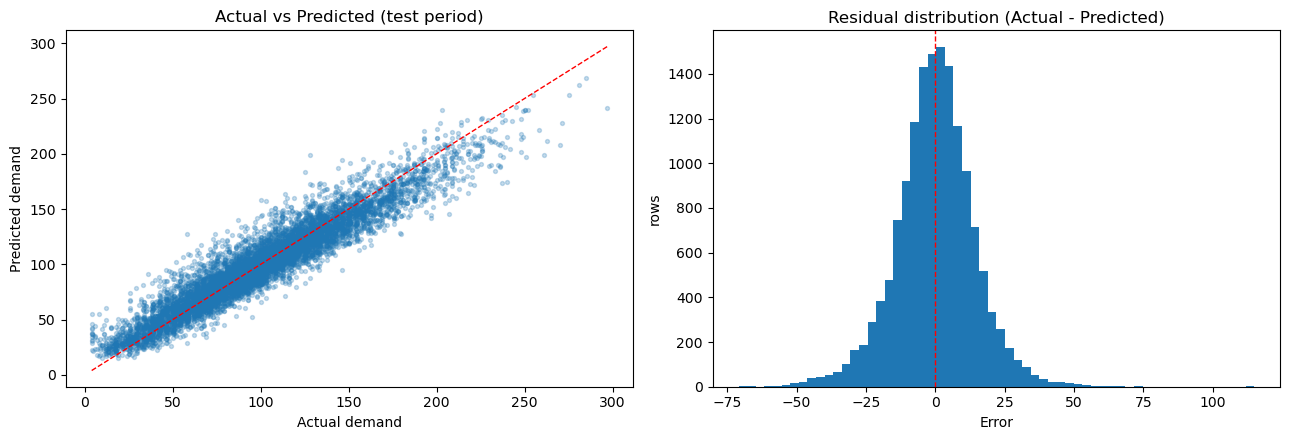


Error by ACTUAL demand band:


,Count,MAE,Mean_Error,Bias_%
Demand Band,,,,
"(-inf, 72.0]",4174,10.3132,-6.6096,-13.3407
"(72.0, 101.0]",3991,9.1664,-2.2367,-2.5660
"(101.0, 134.0]",3865,9.8952,1.2330,1.0560
"(134.0, 168.0]",1978,12.5545,6.8674,4.6049
"(168.0, 238.0]",1034,17.6188,14.0647,7.3683
"(238.0, inf]",58,31.2662,30.1166,11.7028



Error by Product_ID demand tier (tier = quartile of its TRAINING mean demand):


,Count,MAE,Mean_Error,Bias_%
Product_ID demand tier,,,,
Low,3775,9.0454,-0.6788,-0.7584
Medium-low,3775,10.1338,0.2159,0.2193
Medium-high,3775,11.4820,0.1368,0.1322
High,3775,12.4486,-0.1710,-0.1563


-> No material systematic bias for high-demand Product_IDs (-0.2% of their mean demand).


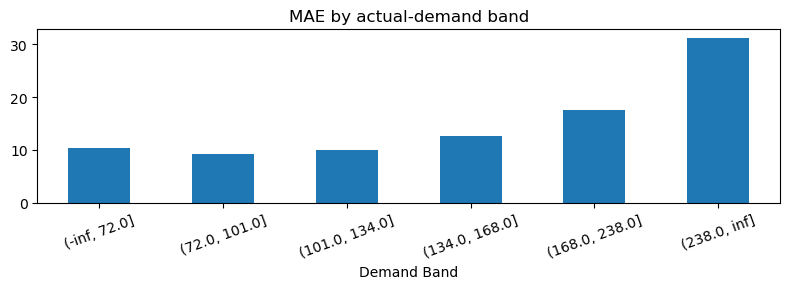

In [15]:
id_columns_present = [c for c in IDENTIFIER_COLUMNS if c in test_df.columns]
analysis_df = test_df[[DATE_COLUMN] + id_columns_present].copy()
analysis_df["Actual"]    = y_test.to_numpy()
analysis_df["Predicted"] = test_pred_raw
analysis_df["Error"]     = analysis_df["Actual"] - analysis_df["Predicted"]
analysis_df["AbsError"]  = analysis_df["Error"].abs()

print(f"Mean error (bias): {analysis_df['Error'].mean():+.3f}  |  as % of mean actual: {analysis_df['Error'].mean() / analysis_df['Actual'].mean() * 100:+.2f}%")
print(f"Median abs error : {analysis_df['AbsError'].median():.3f}  |  90th pct abs error: {analysis_df['AbsError'].quantile(.9):.3f}")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sample = analysis_df.sample(n=min(8000, len(analysis_df)), random_state=RANDOM_STATE)
axes[0].scatter(sample["Actual"], sample["Predicted"], alpha=0.25, s=8)
lims = [min(sample["Actual"].min(), sample["Predicted"].min()), max(sample["Actual"].max(), sample["Predicted"].max())]
axes[0].plot(lims, lims, "r--", linewidth=1)
axes[0].set(title="Actual vs Predicted (test period)", xlabel="Actual demand", ylabel="Predicted demand")
axes[1].hist(analysis_df["Error"], bins=60)
axes[1].axvline(0, color="r", linestyle="--", linewidth=1)
axes[1].set(title="Residual distribution (Actual - Predicted)", xlabel="Error", ylabel="rows")
plt.tight_layout(); plt.show()


def summarise_errors(frame, group):
    out = frame.groupby(group, observed=True).agg(Count=("Error", "size"), MAE=("AbsError", "mean"),
                                                  Mean_Error=("Error", "mean"), Mean_Actual=("Actual", "mean"))
    out["Bias_%"] = out["Mean_Error"] / out["Mean_Actual"] * 100
    return out


# (a) bands of ACTUAL demand; edges come from the TRAINING target distribution
inner_edges = np.unique(np.round(np.quantile(train_df[TARGET_COLUMN], [0.25, 0.5, 0.75, 0.9, 0.99]), 0))
bands = pd.cut(analysis_df["Actual"], bins=np.concatenate([[-np.inf], inner_edges, [np.inf]]), precision=0)
band_table = summarise_errors(analysis_df, bands)
band_table.index = band_table.index.astype(str); band_table.index.name = "Demand Band"
print("\nError by ACTUAL demand band:")
display(band_table[["Count", "MAE", "Mean_Error", "Bias_%"]])

# (b) product demand tiers, assigned from TRAINING averages only
ENTITY_COLUMN = next((c for c in IDENTIFIER_COLUMNS if c in df.columns), None)
tier_table = None
if ENTITY_COLUMN is not None:
    entity_mean = train_df.groupby(ENTITY_COLUMN)[TARGET_COLUMN].mean()
    if len(entity_mean) >= 4:
        tier_labels = ["Low", "Medium-low", "Medium-high", "High"]
        tiers = pd.qcut(entity_mean.rank(method="first"), 4, labels=tier_labels)
        analysis_df["Demand_Tier"] = analysis_df[ENTITY_COLUMN].map(tiers).astype(object)
        tier_table = summarise_errors(analysis_df.dropna(subset=["Demand_Tier"]), "Demand_Tier").reindex(tier_labels)
        tier_table.index.name = f"{ENTITY_COLUMN} demand tier"
        print(f"\nError by {ENTITY_COLUMN} demand tier (tier = quartile of its TRAINING mean demand):")
        display(tier_table[["Count", "MAE", "Mean_Error", "Bias_%"]])
        high_bias = tier_table.loc["High", "Bias_%"]
        if high_bias > 2:
            print(f"-> High-demand {ENTITY_COLUMN}s are UNDER-predicted on average ({high_bias:+.1f}% of their mean demand).")
        elif high_bias < -2:
            print(f"-> High-demand {ENTITY_COLUMN}s are OVER-predicted on average ({high_bias:+.1f}% of their mean demand).")
        else:
            print(f"-> No material systematic bias for high-demand {ENTITY_COLUMN}s ({high_bias:+.1f}% of their mean demand).")
    else:
        print(f"\nFewer than 4 distinct {ENTITY_COLUMN} values - tier analysis skipped.")
else:
    print("\nNo identifier column present - tier analysis skipped.")

band_table["MAE"].plot.bar(figsize=(8, 3), title="MAE by actual-demand band", rot=20)
plt.tight_layout(); plt.show()

## 16. Feature Importance

**Permutation importance** (model-agnostic, so it works for Ridge, forests and boosting alike): shuffle one *raw* input column
and measure how much the MAE gets worse. Because it shuffles raw columns, one-hot / ordinal-encoded categoricals (e.g. `Product_ID`)
appear as **one** feature, not dozens of encoded columns.

> **Interpretation warning:** this is *predictive association*, **not causal impact**. A large value means the model relies on the
> feature to forecast, not that changing it would change demand. Correlated features (e.g. `Price`, `Effective_Price`, `Price_Ratio`)
> share signal, so each one can look weaker than the group really is. Price elasticity is **not** estimated in this notebook.

It is computed on a sample of the test period **after** the final evaluation, to explain the frozen champion; it plays no part in model selection.

Top 15 features for HistGradientBoosting (MAE increase when the feature is shuffled):


,Feature,MAE_Increase,Std
0,Price_Change_Pct,20.3243,0.1384
1,Category,18.7153,0.2308
2,Discount,10.8698,0.1109
3,Product_ID,10.2837,0.0574
4,Previous_Demand,7.3109,0.0553
5,Previous_Price,7.0637,0.0295
6,Price,6.9081,0.1080
7,Store_ID,3.2776,0.0183
8,Competitor_Price,2.5491,0.0221
9,Epidemic,2.4767,0.0447


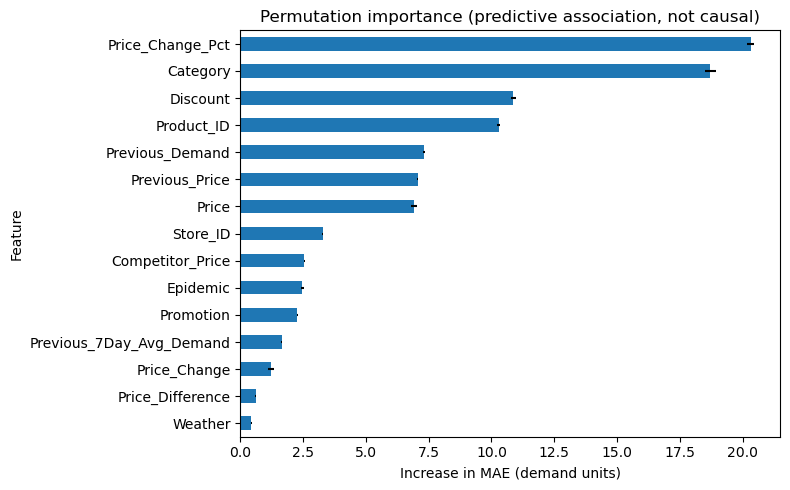

In [16]:
def permutation_importance_table(pipeline, frame, max_rows, n_repeats):
    sample = frame.sample(n=min(max_rows, len(frame)), random_state=RANDOM_STATE)
    result = permutation_importance(pipeline, sample[FEATURE_COLUMNS], sample[TARGET_COLUMN],
                                    scoring="neg_mean_absolute_error", n_repeats=n_repeats,
                                    random_state=RANDOM_STATE, n_jobs=1)
    return (pd.DataFrame({"Feature": FEATURE_COLUMNS,
                          "MAE_Increase": result.importances_mean,
                          "Std": result.importances_std})
            .sort_values("MAE_Increase", ascending=False).reset_index(drop=True))

importance_df = permutation_importance_table(champion_pipeline, test_df, PERMUTATION_MAX_ROWS, PERMUTATION_REPEATS)
top_features = importance_df.head(TOP_N_FEATURES)
print(f"Top {TOP_N_FEATURES} features for {CHAMPION_NAME} (MAE increase when the feature is shuffled):")
display(top_features)

top_features.iloc[::-1].plot.barh(x="Feature", y="MAE_Increase", xerr="Std", legend=False, figsize=(8, 5),
                                  title="Permutation importance (predictive association, not causal)")
plt.xlabel("Increase in MAE (demand units)"); plt.tight_layout(); plt.show()

## 17. Prediction Output

Builds `prediction_df`, clips negative predictions to zero **only here, at the output stage**, runs the sanity checks and saves
`Data/demand_predictions.csv`. Final metrics are computed on exactly what is written to disk.

In [17]:
test_pred = np.clip(test_pred_raw, 0, None)           # demand cannot be negative (output stage only)
n_clipped = int((test_pred_raw < 0).sum())

prediction_df = pd.DataFrame({"Date": test_df[DATE_COLUMN].to_numpy()})
for column in id_columns_present:                      # Product_ID / Store_ID when present
    prediction_df[column] = test_df[column].to_numpy()
prediction_df["Actual_Demand"]    = y_test.to_numpy()
prediction_df["Predicted_Demand"] = test_pred
prediction_df["Error"]            = prediction_df["Actual_Demand"] - prediction_df["Predicted_Demand"]
prediction_df["Absolute_Error"]   = prediction_df["Error"].abs()

final_metrics = regression_metrics(prediction_df["Actual_Demand"], prediction_df["Predicted_Demand"])
print(f"Negative raw predictions clipped to 0: {n_clipped:,}")
print(f"Final test metrics (as saved)  MAE {final_metrics['MAE']:.4f} | RMSE {final_metrics['RMSE']:.4f} | R2 {final_metrics['R2']:.4f}")
print(f"Raw (unclipped) test metrics   MAE {raw_metrics['MAE']:.4f} | RMSE {raw_metrics['RMSE']:.4f} | R2 {raw_metrics['R2']:.4f}")

# ---------------------------- sanity checks ----------------------------
def run_sanity_checks():
    blocked = {normalize_name(c) for c in EXCLUDED_FEATURES + EXTRA_EXCLUDED_FEATURES + LEAKAGE_RISK_COLUMNS}
    again = champion_pipeline.predict(test_df[FEATURE_COLUMNS])
    checks = [
        ("No NaN predictions",                              not prediction_df["Predicted_Demand"].isna().any(), ""),
        ("No negative predicted demand",                    bool((prediction_df["Predicted_Demand"] >= 0).all()), f"{n_clipped} raw negatives clipped"),
        ("Prediction count equals test-set count",          len(prediction_df) == len(test_df), f"{len(prediction_df):,} vs {len(test_df):,}"),
        ("max(train date) < min(test date)",                train_df[DATE_COLUMN].max() < test_df[DATE_COLUMN].min(), ""),
        ("No test date appears in training",                set(train_df[DATE_COLUMN]).isdisjoint(set(test_df[DATE_COLUMN])), ""),
        ("No row shared between train and test",            train_df.index.intersection(test_df.index).empty, ""),
        ("Every fit used only pre-test dates",              max(FIT_LOG) < TEST_START, f"{len(FIT_LOG)} fits, latest date {max(FIT_LOG):%Y-%m-%d}"),
        ("Target is not a model input",                     normalize_name(TARGET_COLUMN) not in {normalize_name(c) for c in FEATURE_COLUMNS}, ""),
        ("No excluded / leakage-risk column is a model input", not any(normalize_name(c) in blocked for c in FEATURE_COLUMNS), ""),
        ("No feature is a near-duplicate of the target",    bool(leakage_audit[leakage_audit["Feature"].isin(FEATURE_COLUMNS)]["AbsCorrWithTarget"].max() < LEAKAGE_CORR_DROP) if not leakage_audit.empty else True, ""),
        ("Pipeline predicts the test data reproducibly",    bool(np.allclose(again, test_pred_raw)), ""),
        ("Actual demand is complete for all test rows",     not prediction_df["Actual_Demand"].isna().any(), ""),
    ]
    report = pd.DataFrame([{"Check": n, "Result": "PASS" if ok else "FAIL", "Detail": d} for n, ok, d in checks])
    display(report)
    failed = report[report["Result"] == "FAIL"]
    if not failed.empty:
        raise AssertionError(f"Sanity checks failed: {failed['Check'].tolist()}")
    print("All sanity checks passed.")

run_sanity_checks()

DATA_DIR.mkdir(parents=True, exist_ok=True)
prediction_df.round({"Actual_Demand": 4, "Predicted_Demand": 4, "Error": 4, "Absolute_Error": 4}).to_csv(PREDICTIONS_PATH, index=False)
print(f"\nSaved predictions -> {PREDICTIONS_PATH}  ({len(prediction_df):,} rows)")
prediction_df.head()

Negative raw predictions clipped to 0: 0
Final test metrics (as saved)  MAE 10.7774 | RMSE 14.2836 | R2 0.8952
Raw (unclipped) test metrics   MAE 10.7774 | RMSE 14.2836 | R2 0.8952


,Check,Result,Detail
0,No NaN predictions,PASS,
1,No negative predicted demand,PASS,0 raw negatives clipped
2,Prediction count equals test-set count,PASS,"15,100 vs 15,100"
3,max(train date) < min(test date),PASS,
4,No test date appears in training,PASS,
5,No row shared between train and test,PASS,
6,Every fit used only pre-test dates,PASS,"32 fits, latest date 2023-09-01"
7,Target is not a model input,PASS,
8,No excluded / leakage-risk column is a model i...,PASS,
9,No feature is a near-duplicate of the target,PASS,


All sanity checks passed.

Saved predictions -> e:\Dynamic_Pricing_Optimizer\Data\demand_predictions.csv  (15,100 rows)


,Date,Product_ID,Store_ID,Actual_Demand,Predicted_Demand,Error,Absolute_Error
0,2023-09-02,P0001,S001,80.0000,78.1753,1.8247,1.8247
1,2023-09-02,P0002,S001,145.0000,161.2708,-16.2708,16.2708
2,2023-09-02,P0003,S001,105.0000,110.8450,-5.8450,5.8450
3,2023-09-02,P0004,S001,83.0000,83.9626,-0.9626,0.9626
4,2023-09-02,P0005,S001,80.0000,88.5781,-8.5781,8.5781


## 18. Save Champion Pipeline

The **complete** pipeline (preprocessing + model) is saved with `joblib`. A downstream app passes raw feature columns
straight to `model.predict()` — no encoders or scalers to recreate.

The save is verified three ways: reload in this process, predict the test set, and — most importantly — load it in a
**fresh Python process** that has none of this notebook's code, which is exactly what Streamlit will do.

In [18]:
MODELS_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(champion_pipeline, MODEL_PATH, compress=3)
print(f"Saved pipeline -> {MODEL_PATH}  ({MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

# 1) reload in this process and predict the whole test set
reloaded_pipeline = joblib.load(MODEL_PATH)
reloaded_pred = reloaded_pipeline.predict(test_df[FEATURE_COLUMNS])
assert np.allclose(reloaded_pred, test_pred_raw), "Reloaded pipeline gives different predictions!"
print(f"Reload check      : OK - predicted {len(reloaded_pred):,} test rows, identical to the in-memory champion")

# 2) load + predict in a brand-new interpreter (no notebook code available)
with tempfile.TemporaryDirectory() as tmp:
    sample_path = Path(tmp) / "sample.pkl"
    test_df[FEATURE_COLUMNS].head(200).to_pickle(sample_path)
    script = ("import sys, json, joblib, pandas as pd\n"
              "model = joblib.load(sys.argv[1]); X = pd.read_pickle(sys.argv[2])\n"
              "print(json.dumps([float(v) for v in model.predict(X)]))")
    proc = subprocess.run([sys.executable, "-c", script, str(MODEL_PATH), str(sample_path)],
                          capture_output=True, text=True)
if proc.returncode != 0:
    raise RuntimeError("Fresh-process load FAILED:\n" + proc.stderr[-1500:])
fresh_pred = np.array(json.loads(proc.stdout.strip().splitlines()[-1]))
assert np.allclose(fresh_pred, test_pred_raw[:200]), "Fresh-process predictions differ!"
print("Fresh-process check: OK - pipeline loads and predicts without any notebook code")

Saved pipeline -> e:\Dynamic_Pricing_Optimizer\Models\demand_forecasting_model.pkl  (1.0 MB)
Reload check      : OK - predicted 15,100 test rows, identical to the in-memory champion
Fresh-process check: OK - pipeline loads and predicts without any notebook code


## 19. Save Model Metadata

`model_metadata.json` is the machine-readable contract for the Streamlit app: which columns to send, their types, and what the model was trained and tested on.

In [19]:
now = datetime.now()
metadata = {
    "model_name": CHAMPION_NAME,
    "model_version": now.strftime("%Y.%m.%d-%H%M"),
    "trained_at": now.isoformat(timespec="seconds"),
    "target_column": TARGET_COLUMN,
    "feature_columns": FEATURE_COLUMNS,
    "numeric_feature_columns": NUMERIC_FEATURES,
    "categorical_feature_columns": CATEGORICAL_FEATURES,
    "identifier_feature_columns": feature_selection["identifier_features"],
    "excluded_features": EXCLUDED_REPORT,
    "feature_input_dtypes": {c: str(df[c].dtype) for c in FEATURE_COLUMNS},
    "training_start_date": f"{train_df[DATE_COLUMN].min():%Y-%m-%d}",
    "training_end_date":   f"{train_df[DATE_COLUMN].max():%Y-%m-%d}",
    "test_start_date":     f"{test_df[DATE_COLUMN].min():%Y-%m-%d}",
    "test_end_date":       f"{test_df[DATE_COLUMN].max():%Y-%m-%d}",
    "MAE":  final_metrics["MAE"],
    "RMSE": final_metrics["RMSE"],
    "R2":   final_metrics["R2"],
    "baseline": {"name": PRIMARY_BASELINE, **baseline_metrics,
                 "mae_improvement_pct": improvement_pct(baseline_metrics["MAE"], final_metrics["MAE"])},
    "time_based_validation": {"n_splits": N_CV_SPLITS, "mean_MAE": float(champion_row["CV MAE"]),
                              "std_MAE": float(champion_row["CV MAE std"])},
    "hyperparameters": CHAMPION_HYPERPARAMETERS,
    "dataset_row_count": int(len(df)),
    "train_row_count": int(len(train_df)),
    "test_row_count": int(len(test_df)),
    "source_file": DATA_PATH.name,
    "column_renames_applied": applied_renames,
    "pipeline_file": MODEL_PATH.name,
    "library_versions": {"scikit_learn": sklearn.__version__, "pandas": pd.__version__,
                         "numpy": np.__version__, "python": sys.version.split()[0]},
    "notes": [
        "The pipeline includes preprocessing: pass RAW feature columns exactly as listed in feature_columns.",
        "Engineered/lag features must be built by the same Feature Engineering logic, using only information available at prediction time.",
        "Predictions should be clipped at 0 (demand cannot be negative).",
        "Feature importance is predictive association, not causal impact. No price elasticity is estimated by this model.",
    ],
}

METADATA_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(METADATA_PATH, "w", encoding="utf-8") as handle:
    json.dump(metadata, handle, indent=2, default=lambda o: o.item() if isinstance(o, np.generic) else str(o))
print(f"Saved metadata -> {METADATA_PATH}")

with open(METADATA_PATH, encoding="utf-8") as handle:
    saved_metadata = json.load(handle)
required_keys = ["model_name", "target_column", "feature_columns", "numeric_feature_columns", "categorical_feature_columns",
                 "training_start_date", "training_end_date", "test_start_date", "test_end_date",
                 "MAE", "RMSE", "R2", "dataset_row_count", "model_version"]
missing_keys = [k for k in required_keys if k not in saved_metadata]
assert not missing_keys, f"Metadata is missing keys: {missing_keys}"
assert set(saved_metadata["feature_columns"]) == set(reloaded_pipeline.feature_names_in_), "Metadata/pipeline feature mismatch"
print("Metadata reload check: OK (all required keys present; features match the saved pipeline)")

Saved metadata -> e:\Dynamic_Pricing_Optimizer\Models\model_metadata.json
Metadata reload check: OK (all required keys present; features match the saved pipeline)


## 20. Model Input Contract

What the Streamlit app (or any consumer) must provide to `demand_forecasting_model.pkl`.
Printed from the **saved metadata file**, so it is exactly what a downstream app will read.

```python
model = joblib.load("Models/demand_forecasting_model.pkl")
meta  = json.load(open("Models/model_metadata.json"))
X     = input_df[meta["feature_columns"]]            # raw columns, no manual encoding/scaling
demand_forecast = np.clip(model.predict(X), 0, None)
```

In [20]:
def print_input_contract(meta):
    line = "=" * 78
    print(line); print("MODEL INPUT CONTRACT"); print(line)
    print(f"Model   : {meta['model_name']}   (version {meta['model_version']})")
    print(f"Target  : {meta['target_column']}   (output; NEVER an input)\n")
    print(f"Required model input features ({len(meta['feature_columns'])}):")
    print("  " + ", ".join(meta["feature_columns"]))
    print(f"\nNumeric features ({len(meta['numeric_feature_columns'])}):")
    print("  " + ", ".join(meta["numeric_feature_columns"]))
    print(f"\nCategorical features ({len(meta['categorical_feature_columns'])}) - identifiers are categorical, never numeric:")
    print("  " + ", ".join(meta["categorical_feature_columns"]))
    print(f"\nExcluded features ({len(meta['excluded_features'])}):")
    for column, reason in meta["excluded_features"].items():
        print(f"  - {column:<28} {reason}")
    print("\nRules for consumers:")
    for note in meta["notes"]:
        print("  * " + note)
    print(line)

print_input_contract(saved_metadata)
display(pd.DataFrame({"Raw input dtype at training": saved_metadata["feature_input_dtypes"]}))

MODEL INPUT CONTRACT
Model   : HistGradientBoosting   (version 2026.10.07-1645)
Target  : Demand   (output; NEVER an input)

Required model input features (32):
  Store_ID, Product_ID, Category, Region, Inventory, Price, Discount, Weather, Promotion, Competitor_Price, Seasonality, Epidemic, Year, Month, Day, DayOfWeek, WeekOfYear, Quarter, IsWeekend, Previous_Price, Price_Change, Price_Change_Pct, Effective_Price, Price_Difference, Price_Ratio, Previous_Demand, Previous_7Day_Avg_Demand, Demand_Trend, Inventory_Coverage_Days, Low_Inventory, Weekend_Promotion, Promotion_Discount

Numeric features (26):
  Inventory, Price, Discount, Promotion, Competitor_Price, Epidemic, Year, Month, Day, DayOfWeek, WeekOfYear, Quarter, IsWeekend, Previous_Price, Price_Change, Price_Change_Pct, Effective_Price, Price_Difference, Price_Ratio, Previous_Demand, Previous_7Day_Avg_Demand, Demand_Trend, Inventory_Coverage_Days, Low_Inventory, Weekend_Promotion, Promotion_Discount

Categorical features (6) - ide

,Raw input dtype at training
Store_ID,object
Product_ID,object
Category,object
Region,object
Inventory,float64
Price,float64
Discount,float64
Weather,object
Promotion,int64
Competitor_Price,float64


## 21. Final Summary

First, the new result is compared with the **historical reference** (a fixed 29-feature model). The historical numbers are a
reference point only — the generic pipeline is *not* expected to reproduce them, because the feature selection, the encoding
(IDs are now true categoricals, rare levels pooled) and the split boundary were all redesigned.

In [21]:
# ---------------- comparison with the historical reference ----------------
hist = HISTORICAL_REFERENCE
comp = pd.DataFrame({
    "Historical": [hist["MAE"], hist["RMSE"], hist["R2"]],
    "New (generic pipeline)": [final_metrics["MAE"], final_metrics["RMSE"], final_metrics["R2"]],
}, index=["MAE", "RMSE", "R2"])
comp["Difference"] = comp["New (generic pipeline)"] - comp["Historical"]
comp["Difference %"] = comp["Difference"] / comp["Historical"] * 100
print("New result vs historical reference:")
display(comp)

legacy_in_use = [c for c in LEGACY_FEATURES if c in FEATURE_COLUMNS]
print(f"Features shared with the legacy model : {len(legacy_in_use)} of {len(LEGACY_FEATURES)}")
print(f"Legacy features no longer used        : {[c for c in LEGACY_FEATURES if c not in FEATURE_COLUMNS] or 'none'}")
print(f"New features not in the legacy model  : {[c for c in FEATURE_COLUMNS if c not in LEGACY_FEATURES] or 'none'}")
print(f"Split boundary: new test starts {TEST_START:%Y-%m-%d}; legacy test started {LEGACY_SPLIT_DATE}")

# ---- diagnostic: same champion configuration on the LEGACY split date (nothing here is saved or used for selection)
legacy_diag = None
legacy_cut = pd.Timestamp(LEGACY_SPLIT_DATE)
if RUN_LEGACY_SPLIT_DIAGNOSTIC and df[DATE_COLUMN].min() < legacy_cut <= TEST_START:
    legacy_train = df[df[DATE_COLUMN] < legacy_cut]
    legacy_eval  = df[df[DATE_COLUMN] >= legacy_cut]
    diag_pipe = clone(make_pipeline(CHAMPION_KEY, NUMERIC_FEATURES, CATEGORICAL_FEATURES, **CHAMPION_PARAMS))
    diag_pipe.fit(legacy_train[FEATURE_COLUMNS], legacy_train[TARGET_COLUMN])      # pre-2023-08 rows only
    legacy_diag = regression_metrics(legacy_eval[TARGET_COLUMN], diag_pipe.predict(legacy_eval[FEATURE_COLUMNS]))
    print(f"\nDiagnostic - champion configuration on the legacy split ({LEGACY_SPLIT_DATE}): "
          f"MAE {legacy_diag['MAE']:.2f} | RMSE {legacy_diag['RMSE']:.2f} | R2 {legacy_diag['R2']:.3f}")

delta = comp.loc["MAE", "Difference %"]
print("\nInterpretation:")
if abs(delta) <= 5:
    print(f"* New MAE is within 5% of the historical value ({delta:+.1f}%): the redesign did not materially change accuracy.")
else:
    print(f"* New MAE is {abs(delta):.1f}% {'LOWER (better)' if delta < 0 else 'HIGHER (worse)'} than the historical value.")
if legacy_diag is not None:
    gap_split = (final_metrics["MAE"] - legacy_diag["MAE"]) / legacy_diag["MAE"] * 100
    gap_pipe = (legacy_diag["MAE"] - hist["MAE"]) / hist["MAE"] * 100
    print(f"* Test-window effect: the same champion scores {gap_split:+.1f}% MAE on the new test window vs the legacy window "
          "(different days are being forecast).")
    print(f"* Pipeline effect: on the legacy window the new pipeline's MAE is {abs(gap_pipe):.1f}% "
          f"{'lower' if gap_pipe < 0 else 'higher'} than the historical MAE - this isolates the feature-set, encoding and tuning changes.")
print("* In the legacy notebook the model family (Random Forest vs HistGradientBoosting) was compared on the test window before tuning; "
      "here every selection decision uses training-period validation only, so the new figure is the more conservative estimate.")

New result vs historical reference:


,Historical,New (generic pipeline),Difference,Difference %
MAE,13.7500,10.7774,-2.9726,-21.6186
RMSE,17.9400,14.2836,-3.6564,-20.3813
R2,0.8470,0.8952,0.0482,5.6872


Features shared with the legacy model : 29 of 29
Legacy features no longer used        : none
New features not in the legacy model  : ['WeekOfYear', 'Quarter', 'Previous_Price']
Split boundary: new test starts 2023-09-02; legacy test started 2023-08-01

Diagnostic - champion configuration on the legacy split (2023-08-01): MAE 10.94 | RMSE 14.53 | R2 0.900

Interpretation:
* New MAE is 21.6% LOWER (better) than the historical value.
* Test-window effect: the same champion scores -1.5% MAE on the new test window vs the legacy window (different days are being forecast).
* Pipeline effect: on the legacy window the new pipeline's MAE is 20.5% lower than the historical MAE - this isolates the feature-set, encoding and tuning changes.
* In the legacy notebook the model family (Random Forest vs HistGradientBoosting) was compared on the test window before tuning; here every selection decision uses training-period validation only, so the new figure is the more conservative estimate.


In [22]:
# ---------------- final summary ----------------
line = "=" * 78
print(line); print("FINAL SUMMARY"); print(line)
print(f"Dataset shape      : {df.shape}   ({DATA_PATH.name})")
print(f"Train / Test rows  : {len(train_df):,} / {len(test_df):,}   "
      f"(train {train_df[DATE_COLUMN].min():%Y-%m-%d} -> {train_df[DATE_COLUMN].max():%Y-%m-%d};"
      f" test {test_df[DATE_COLUMN].min():%Y-%m-%d} -> {test_df[DATE_COLUMN].max():%Y-%m-%d})")
print(f"Features used      : {len(FEATURE_COLUMNS)}  ({len(NUMERIC_FEATURES)} numeric, {len(CATEGORICAL_FEATURES)} categorical)")
print(f"\nBaseline ({PRIMARY_BASELINE}) on test: MAE {baseline_metrics['MAE']:.3f} | RMSE {baseline_metrics['RMSE']:.3f} | R2 {baseline_metrics['R2']:.3f}")

print("\nCandidate comparison (time-based validation, expanding window; lower MAE is better):")
display(cv_results[["Model", "Config", "CV MAE", "CV RMSE", "CV R2"]].head(8))

print(f"Champion model     : {CHAMPION_NAME}  {CHAMPION_PARAMS if CHAMPION_PARAMS else '(default settings)'}")
print(f"Final test MAE     : {final_metrics['MAE']:.3f}")
print(f"Final test RMSE    : {final_metrics['RMSE']:.3f}")
print(f"Final test R2      : {final_metrics['R2']:.3f}")
print(f"MAE vs baseline    : {improvement_pct(baseline_metrics['MAE'], final_metrics['MAE']):+.1f}% improvement")
print(f"\nTop features (permutation importance - predictive association, not causal):")
for rank, row in importance_df.head(5).iterrows():
    print(f"  {rank + 1}. {row['Feature']:<28} +{row['MAE_Increase']:.3f} MAE when shuffled")
print("\nSaved artifacts:")
for path in (PREDICTIONS_PATH, MODEL_PATH, METADATA_PATH):
    print(f"  {'OK ' if path.exists() else 'MISSING'}  {path}")
assert all(p.exists() for p in (PREDICTIONS_PATH, MODEL_PATH, METADATA_PATH)), "An expected artifact is missing."
print(f"\nTest set untouched during training: {len(FIT_LOG)} model fits, latest training date {max(FIT_LOG):%Y-%m-%d} < test start {TEST_START:%Y-%m-%d}")
print(line)

FINAL SUMMARY
Dataset shape      : (75300, 36)   (demand_forecasting_engineered.csv)
Train / Test rows  : 60,200 / 15,100   (train 2022-01-08 -> 2023-09-01; test 2023-09-02 -> 2024-01-30)
Features used      : 32  (26 numeric, 6 categorical)

Baseline (Baseline: Previous_Demand (naive)) on test: MAE 40.138 | RMSE 51.894 | R2 -0.384

Candidate comparison (time-based validation, expanding window; lower MAE is better):


,Model,Config,CV MAE,CV RMSE,CV R2
0,HistGradientBoosting,variant 3,12.4478,16.6120,0.8752
1,HistGradientBoosting,variant 4,13.7416,18.1843,0.8506
2,HistGradientBoosting,variant 1,13.8120,18.2379,0.8498
3,HistGradientBoosting,default,13.8517,18.3037,0.8486
4,HistGradientBoosting,variant 2,15.1878,19.8554,0.8218
5,Random Forest,default,17.4887,22.7958,0.7654
6,Ridge Regression,default,18.3881,23.8107,0.7402


Champion model     : HistGradientBoosting  {'max_leaf_nodes': 63}
Final test MAE     : 10.777
Final test RMSE    : 14.284
Final test R2      : 0.895
MAE vs baseline    : +73.1% improvement

Top features (permutation importance - predictive association, not causal):
  1. Price_Change_Pct             +20.324 MAE when shuffled
  2. Category                     +18.715 MAE when shuffled
  3. Discount                     +10.870 MAE when shuffled
  4. Product_ID                   +10.284 MAE when shuffled
  5. Previous_Demand              +7.311 MAE when shuffled

Saved artifacts:
  OK   e:\Dynamic_Pricing_Optimizer\Data\demand_predictions.csv
  OK   e:\Dynamic_Pricing_Optimizer\Models\demand_forecasting_model.pkl
  OK   e:\Dynamic_Pricing_Optimizer\Models\model_metadata.json

Test set untouched during training: 32 model fits, latest training date 2023-09-01 < test start 2023-09-02
